# Earthquake Location-Based Seismic Risk Estimation (Python + Scikit-learn ML)

**Goal:** Explore historical earthquake activity by location, train an ML model for a clearly defined historical-activity category, and provide a function/UI-ready workflow for estimating relative seismic activity for a selected latitude/longitude.

> **Important limitation:** This notebook does not predict an imminent earthquake or provide a scientifically reliable probability that an earthquake will occur at a particular place and time. The categories are *relative historical-activity indicators* based on the available catalog. For real-world safety decisions, use official seismic hazard maps and authorities.

**Input file:** `scraped_earthquake_data.csv` in the same folder. The notebook tries to identify common column-name variants; check the mapping output and adjust it if necessary.

## 1. Install and import libraries

In [1]:
# Run once if needed
%pip install pandas numpy matplotlib seaborn scikit-learn scipy ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)


## Optional: Fetch earthquake data from the USGS API (COMMENTED OUT)

The following cell is intentionally **commented out** and will not run during normal notebook execution. Uncomment it only if you want to download a fresh CSV from the USGS Earthquake Catalog API. Adjust the date range and filters as needed. The API response is saved to `scraped_earthquake_data.csv`, which is the file loaded in the next section.

In [ ]:
# OPTIONAL DATA COLLECTION — INTENTIONALLY COMMENTED OUT
# This block does nothing unless you remove the leading `#` characters.
#
# import requests
#
# USGS_API_URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
# params = {
#     "format": "csv",
#     "starttime": "2020-01-01",
#     "endtime": "2025-12-31",
#     "minmagnitude": 4.0,
#     "orderby": "time-asc",
# }
#
# response = requests.get(USGS_API_URL, params=params, timeout=120)
# response.raise_for_status()
# output_csv = "scraped_earthquake_data.csv"
# with open(output_csv, "wb") as file:
#     file.write(response.content)
# print(f"Saved USGS earthquake catalog to {output_csv}")
# print("Request URL:", response.url)


## 2. Load and inspect the dataset

In [4]:
FILE_PATH = "scraped_earthquake_data.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"Could not find {FILE_PATH}. Put the CSV in the same folder as this notebook."
    )

raw = pd.read_csv(FILE_PATH, low_memory=False)
print("Shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"column": raw.columns, "dtype": [str(x) for x in raw.dtypes]}))

Shape: (93931, 19)


,event_id,time_utc,magnitude,place,longitude,latitude,depth_km,felt,cdi,mmi,tsunami,significance,station_count,azimuthal_gap,nearest_station_deg,rms,magnitude_type,review_status,event_url
0,us6000d4p7,2021-01-01 00:40:35.586000+00:00,5.3,southern Mid-Atlantic Ridge,-4.7622,-52.2909,10.00,NaN,NaN,0.0,0,432,NaN,34.0,16.126,0.77,mww,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
1,us6000d7q1,2021-01-01 01:13:18.272000+00:00,4.4,"13 km NE of Yigo Village, Guam",144.9621,13.6330,162.73,NaN,NaN,NaN,0,298,NaN,146.0,0.100,0.74,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
2,us6000d4pp,2021-01-01 01:20:09.649000+00:00,5.0,Kermadec Islands region,-177.9341,-31.3191,10.00,NaN,NaN,NaN,0,385,NaN,86.0,2.067,0.91,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
3,us6000d4pq,2021-01-01 01:50:22.753000+00:00,4.1,"28 km SSE of Farkh?r, Afghanistan",69.9285,36.3240,139.79,NaN,NaN,NaN,0,259,NaN,86.0,1.920,0.69,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
4,us6000d7q2,2021-01-01 01:50:51.107000+00:00,4.4,"Izu Islands, Japan region",142.0702,30.6110,10.00,NaN,NaN,NaN,0,298,NaN,128.0,3.149,0.70,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...


,column,dtype
0,event_id,object
1,time_utc,object
2,magnitude,float64
3,place,object
4,longitude,float64
5,latitude,float64
6,depth_km,float64
7,felt,float64
8,cdi,float64
9,mmi,float64


### EDA dashboard: how many earthquakes have been recorded so far?

This shows the **number of earthquake records present in your CSV** (not a live global count). If your data has a country column, it also displays country-wise counts. If there is no country column, country-wise analysis needs a country field or a separate reverse-geocoding/data-enrichment step.

In [5]:
# Total records currently available in the loaded dataset
print(f"Earthquake records currently in this CSV: {len(raw):,}")

# Detect an existing country column if the dataset contains one
def find_existing_country_col(columns):
    aliases = {"country", "countryname", "nation", "locationcountry"}
    for col in columns:
        norm = "".join(ch.lower() for ch in str(col) if ch.isalnum())
        if norm in aliases:
            return col
    return None

COUNTRY_SOURCE_COL = find_existing_country_col(raw.columns)
if COUNTRY_SOURCE_COL:
    country_counts = (
        raw[COUNTRY_SOURCE_COL].fillna("Unknown").astype(str)
        .value_counts().rename_axis("Country").reset_index(name="Earthquake records")
    )
    display(country_counts.head(20))
    plt.figure(figsize=(12, 6))
    country_counts.head(15).sort_values("Earthquake records").plot(
        kind="barh", x="Country", y="Earthquake records", legend=False
    )
    plt.title("Top countries by earthquake records in this dataset")
    plt.xlabel("Number of records")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()
else:
    print("No country column found in the CSV, so country-wise counts cannot be calculated yet.")
    print("Latitude/longitude alone do not reliably identify a country without a geographic boundary dataset or reverse geocoding.")

Earthquake records currently in this CSV: 93,931
No country column found in the CSV, so country-wise counts cannot be calculated yet.
Latitude/longitude alone do not reliably identify a country without a geographic boundary dataset or reverse geocoding.


## 3. Standardize column names and identify important fields

The model needs latitude, longitude, magnitude, and preferably event date/time and depth. If automatic mapping chooses the wrong columns, edit `COLUMN_MAP` manually.

In [6]:
def normalize_name(name):
    return "".join(ch.lower() for ch in str(name) if ch.isalnum())

normalized = {normalize_name(c): c for c in raw.columns}

def find_col(candidates):
    for candidate in candidates:
        if normalize_name(candidate) in normalized:
            return normalized[normalize_name(candidate)]
    return None

COLUMN_MAP = {
    "latitude": find_col(["latitude", "lat"]),
    "longitude": find_col(["longitude", "lon", "lng", "long"]),
    "magnitude": find_col(["magnitude", "mag", "magvalue", "震级"]),
    "depth": find_col(["depth", "depthkm", "depth_km"]),
    "time": find_col(["time", "date", "datetime", "timestamp", "eventtime", "origin_time"]),
    "event_id": find_col(["id", "eventid", "earthquakeid", "code"]),
}
display(pd.DataFrame({"required_field": COLUMN_MAP.keys(), "detected_column": COLUMN_MAP.values()}))

for required in ["latitude", "longitude", "magnitude"]:
    if COLUMN_MAP[required] is None:
        raise ValueError(
            f"Could not detect {required}. Edit COLUMN_MAP using the actual CSV column name."
        )

,required_field,detected_column
0,latitude,latitude
1,longitude,longitude
2,magnitude,magnitude
3,depth,depth_km
4,time,None
5,event_id,event_id


## 4. Clean records

In [7]:
df = raw.copy()
rename_map = {source: target for target, source in COLUMN_MAP.items() if source is not None}
df = df.rename(columns=rename_map)

for col in ["latitude", "longitude", "magnitude", "depth"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "time" in df.columns:
    df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)
    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month
    df["hour"] = df["time"].dt.hour

before = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=["latitude", "longitude", "magnitude"])
df = df[df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)]
df = df[df["magnitude"].between(-2, 10)]
print("Rows before cleaning:", before)
print("Rows after cleaning:", len(df))
print("Rows removed:", before - len(df))
display(df.head())

Rows before cleaning: 93931
Rows after cleaning: 93931
Rows removed: 0


,event_id,time_utc,magnitude,place,longitude,latitude,depth,felt,cdi,mmi,tsunami,significance,station_count,azimuthal_gap,nearest_station_deg,rms,magnitude_type,review_status,event_url
0,us6000d4p7,2021-01-01 00:40:35.586000+00:00,5.3,southern Mid-Atlantic Ridge,-4.7622,-52.2909,10.00,NaN,NaN,0.0,0,432,NaN,34.0,16.126,0.77,mww,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
1,us6000d7q1,2021-01-01 01:13:18.272000+00:00,4.4,"13 km NE of Yigo Village, Guam",144.9621,13.6330,162.73,NaN,NaN,NaN,0,298,NaN,146.0,0.100,0.74,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
2,us6000d4pp,2021-01-01 01:20:09.649000+00:00,5.0,Kermadec Islands region,-177.9341,-31.3191,10.00,NaN,NaN,NaN,0,385,NaN,86.0,2.067,0.91,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
3,us6000d4pq,2021-01-01 01:50:22.753000+00:00,4.1,"28 km SSE of Farkh?r, Afghanistan",69.9285,36.3240,139.79,NaN,NaN,NaN,0,259,NaN,86.0,1.920,0.69,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
4,us6000d7q2,2021-01-01 01:50:51.107000+00:00,4.4,"Izu Islands, Japan region",142.0702,30.6110,10.00,NaN,NaN,NaN,0,298,NaN,128.0,3.149,0.70,mb,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...


## 5. Exploratory analysis

,count,mean,std,min,25%,50%,75%,max
latitude,93931.0,4.389006,30.671444,-84.4932,-19.03745,1.7934,30.3231,87.3752
longitude,93931.0,39.626308,121.270617,-179.9997,-69.72615,98.4674,141.9317,179.9994
magnitude,93931.0,4.516825,0.388782,4.0000,4.30000,4.4000,4.7000,8.8000
depth,93931.0,81.770628,134.996387,-1.9200,10.00000,23.8200,87.1685,683.5780


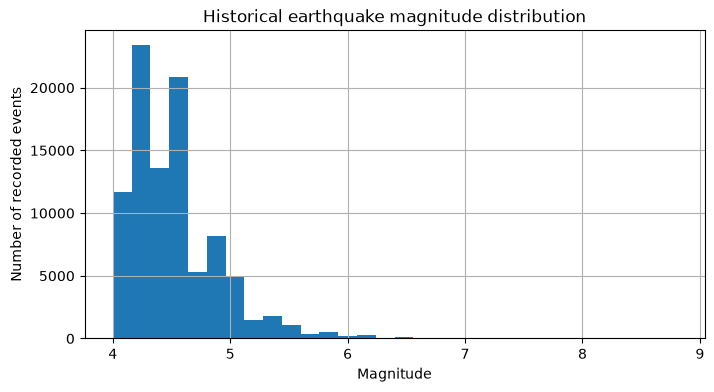

In [8]:
display(df[["latitude", "longitude", "magnitude"] + (["depth"] if "depth" in df.columns else [])].describe().T)

plt.figure(figsize=(8, 4))
df["magnitude"].dropna().hist(bins=30)
plt.title("Historical earthquake magnitude distribution")
plt.xlabel("Magnitude")
plt.ylabel("Number of recorded events")
plt.show()

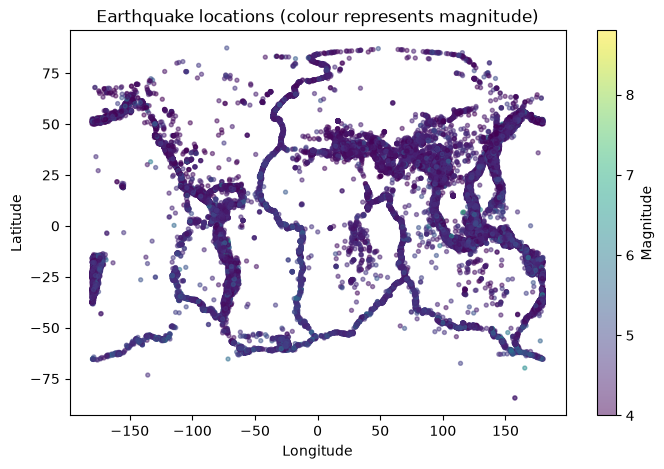

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df["longitude"], df["latitude"], c=df["magnitude"], s=8, alpha=0.5)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Earthquake locations (colour represents magnitude)")
plt.colorbar(label="Magnitude")
plt.show()

## 6. Build a location-based grid

We aggregate historical events into geographic grid cells. A grid cell is a practical approximation for location-level analysis; it is not a precise fault or geological boundary. Choose a grid size appropriate for the geographic coverage and dataset density.

In [10]:
GRID_DEGREES = 0.5  # Try 0.25 for finer cells if there are enough records

df["lat_cell"] = np.floor(df["latitude"] / GRID_DEGREES) * GRID_DEGREES
df["lon_cell"] = np.floor(df["longitude"] / GRID_DEGREES) * GRID_DEGREES

# Magnitude bands are descriptive target classes, not official safety ratings.
def activity_band(m):
    if m < 3.0:
        return "Lower"
    elif m < 5.0:
        return "Moderate"
    else:
        return "High"

df["magnitude_band"] = df["magnitude"].apply(activity_band)

group_cols = ["lat_cell", "lon_cell"]
agg_dict = {
    "event_count": ("magnitude", "size"),
    "mean_magnitude": ("magnitude", "mean"),
    "max_magnitude": ("magnitude", "max"),
    "std_magnitude": ("magnitude", "std"),
}
if "depth" in df.columns:
    agg_dict["mean_depth"] = ("depth", "mean")

grid = df.groupby(group_cols).agg(**agg_dict).reset_index()
grid["std_magnitude"] = grid["std_magnitude"].fillna(0)
grid["activity_band"] = grid["max_magnitude"].apply(activity_band)

display(grid.sort_values("event_count", ascending=False).head(10))
print("Grid cells:", len(grid))

,lat_cell,lon_cell,event_count,mean_magnitude,max_magnitude,std_magnitude,mean_depth,activity_band
11783,52.5,160.5,374,4.546524,7.4,0.462626,20.843056,High
6309,8.0,126.5,356,4.657303,6.8,0.414698,58.795795,High
3000,-18.0,-179.0,352,4.338352,5.9,0.290261,561.732310,High
2384,-24.5,-67.5,349,4.318911,5.9,0.206470,188.364364,High
11701,52.0,160.5,324,4.524383,6.0,0.376793,15.694673,High
9736,36.5,25.5,307,4.336482,5.3,0.266000,10.006984,High
5637,1.0,126.0,293,4.587031,7.4,0.411607,36.845857,High
11700,52.0,160.0,291,4.608247,8.8,0.447831,25.758687,High
11548,51.0,159.5,291,4.512715,5.7,0.316353,15.249832,High
7932,23.5,121.5,283,4.633216,7.4,0.458752,18.517912,High


Grid cells: 12769


## 8. Train and compare multiple classification models

The target (`risk_category`) is created from quantiles of each grid cell's `event_count`. To avoid directly giving the target-generating column to the classifiers, `event_count` is retained for reporting but **excluded from the predictor features**. The target is still derived from historical counts, so this remains a relative historical-category classification exercise—not a future earthquake forecast.

Five classifiers are trained on the same stratified train/test split and compared using accuracy, weighted precision, weighted recall, and weighted F1-score. The model with the highest weighted F1-score is selected for the confusion matrix and location-independent evaluation.

In [12]:
import numpy as np
import pandas as pd

# 1. Check required columns
print("Available columns:", grid.columns.tolist())

if "event_count" not in grid.columns:
    raise KeyError(
        "'event_count' missing from grid. "
        "Run the geographic aggregation cell first."
    )

# 2. Create risk_category if it does not exist
if "risk_category" not in grid.columns:
    q1 = grid["event_count"].quantile(0.25)
    q2 = grid["event_count"].quantile(0.50)
    q3 = grid["event_count"].quantile(0.75)

    grid["risk_category"] = pd.cut(
        grid["event_count"],
        bins=[-np.inf, q1, q2, q3, np.inf],
        labels=[
            "Safe / Lower historical activity",
            "Normal",
            "Moderate",
            "Severe / Higher historical activity"
        ],
        include_lowest=True
    )

# 3. Define predictor features
feature_cols = [
    "lat_cell",
    "lon_cell",
    "mean_magnitude",
    "max_magnitude",
    "std_magnitude"
]

if "mean_depth" in grid.columns:
    feature_cols.append("mean_depth")

# Check that features exist
missing = [col for col in feature_cols if col not in grid.columns]

if missing:
    raise KeyError(f"Missing predictor columns: {missing}")

# 4. Create ML dataset
# Keep event_count for analysis, but exclude it from X
ml = grid[feature_cols + ["event_count", "risk_category"]].copy()

ml = ml.replace([np.inf, -np.inf], np.nan)
ml = ml.dropna(subset=feature_cols + ["risk_category"])

print("ML rows:", len(ml))
print("Predictor features:", feature_cols)
print("Target distribution:")
print(ml["risk_category"].value_counts())

display(ml.head())

Available columns: ['lat_cell', 'lon_cell', 'event_count', 'mean_magnitude', 'max_magnitude', 'std_magnitude', 'mean_depth', 'activity_band']
ML rows: 12769
Predictor features: ['lat_cell', 'lon_cell', 'mean_magnitude', 'max_magnitude', 'std_magnitude', 'mean_depth']
Target distribution:
risk_category
Safe / Lower historical activity       4945
Severe / Higher historical activity    2964
Moderate                               2905
Normal                                 1955
Name: count, dtype: int64


,lat_cell,lon_cell,mean_magnitude,max_magnitude,std_magnitude,mean_depth,event_count,risk_category
0,-84.5,157.0,4.4,4.4,0.0,10.0,1,Safe / Lower historical activity
1,-84.5,157.5,4.4,4.4,0.0,10.0,1,Safe / Lower historical activity
2,-73.5,-136.0,4.6,4.6,0.0,10.0,1,Safe / Lower historical activity
3,-70.0,165.0,6.3,6.3,0.0,14.0,1,Safe / Lower historical activity
4,-67.5,114.0,4.9,4.9,0.0,10.0,1,Safe / Lower historical activity


In [13]:
# Use one fixed split for a fair comparison across classifiers.
X = ml[feature_cols]
y = ml["risk_category"]

class_counts = y.value_counts()
stratify_labels = y if (len(class_counts) > 1 and class_counts.min() >= 2) else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_labels
)

classifiers = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, random_state=42, class_weight="balanced"
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100, max_depth=8, random_state=42, class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=3, random_state=42
    ),
}

trained_models = {}
results = []

for model_name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)
    trained_models[model_name] = clf
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Weighted Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test, predictions, average="weighted", zero_division=0),
    })

comparison = pd.DataFrame(results).sort_values(
    ["Weighted F1", "Accuracy"], ascending=False
).reset_index(drop=True)

best_model_name = comparison.loc[0, "Model"]
model = trained_models[best_model_name]
y_pred = model.predict(X_test)

print("Model comparison on the same held-out test set:")
display(comparison.style.format({
    "Accuracy": "{:.3f}",
    "Weighted Precision": "{:.3f}",
    "Weighted Recall": "{:.3f}",
    "Weighted F1": "{:.3f}",
}))
print(f"Selected model by weighted F1 (tie-break: accuracy): {best_model_name}")
print("Reminder: this is a relative historical-category classification task, not a future earthquake forecast.")

Model comparison on the same held-out test set:


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Gradient Boosting,0.916,0.916,0.916,0.915
1,Logistic Regression,0.868,0.869,0.868,0.866
2,Random Forest,0.863,0.862,0.863,0.862
3,Decision Tree,0.847,0.851,0.847,0.846
4,Extra Trees,0.815,0.808,0.815,0.809


Selected model by weighted F1 (tie-break: accuracy): Gradient Boosting
Reminder: this is a relative historical-category classification task, not a future earthquake forecast.


In [14]:
# Keep rows with enough information for ML
feature_cols = ["lat_cell", "lon_cell", "event_count", "mean_magnitude", "max_magnitude", "std_magnitude"]
if "mean_depth" in grid.columns:
    feature_cols.append("mean_depth")

ml = grid[feature_cols + ["risk_category"]].copy()
ml = ml.replace([np.inf, -np.inf], np.nan).dropna()
print("ML rows:", len(ml))
display(ml.head())

ML rows: 12769


,lat_cell,lon_cell,event_count,mean_magnitude,max_magnitude,std_magnitude,mean_depth,risk_category
0,-84.5,157.0,1,4.4,4.4,0.0,10.0,Safe / Lower historical activity
1,-84.5,157.5,1,4.4,4.4,0.0,10.0,Safe / Lower historical activity
2,-73.5,-136.0,1,4.6,4.6,0.0,10.0,Safe / Lower historical activity
3,-70.0,165.0,1,6.3,6.3,0.0,14.0,Safe / Lower historical activity
4,-67.5,114.0,1,4.9,4.9,0.0,10.0,Safe / Lower historical activity


,Predicted: Moderate,Predicted: Normal,Predicted: Safe / Lower historical activity,Predicted: Severe / Higher historical activity
Actual: Moderate,499,10,2,70
Actual: Normal,11,337,43,0
Actual: Safe / Lower historical activity,0,0,989,0
Actual: Severe / Higher historical activity,77,2,0,514



Class-level report for Gradient Boosting:
                                     precision    recall  f1-score   support

                           Moderate       0.85      0.86      0.85       581
                             Normal       0.97      0.86      0.91       391
   Safe / Lower historical activity       0.96      1.00      0.98       989
Severe / Higher historical activity       0.88      0.87      0.87       593

                           accuracy                           0.92      2554
                          macro avg       0.91      0.90      0.90      2554
                       weighted avg       0.92      0.92      0.92      2554



<Figure size 900x400 with 0 Axes>

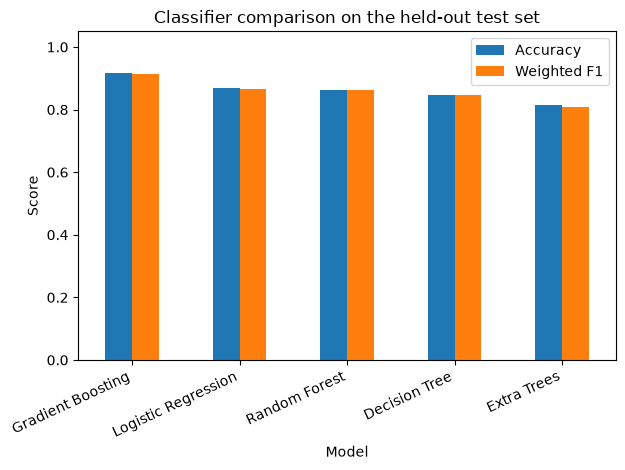

In [15]:
# Confusion matrix and class-level report for the selected best model
labels = list(model.classes_)
cm = confusion_matrix(y_test, y_pred, labels=labels)
display(pd.DataFrame(cm, index=[f"Actual: {x}" for x in labels],
                     columns=[f"Predicted: {x}" for x in labels]))
print(f"\nClass-level report for {best_model_name}:")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

plt.figure(figsize=(9, 4))
comparison.set_index("Model")[["Accuracy", "Weighted F1"]].plot(kind="bar")
plt.title("Classifier comparison on the held-out test set")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 9. Inspect class-level results

In [16]:
# Confusion matrix from holdout predictions
labels = list(model.classes_)
cm = confusion_matrix(y_test, y_pred, labels=labels)
display(pd.DataFrame(cm, index=[f"Actual: {x}" for x in labels],
                     columns=[f"Predicted: {x}" for x in labels]))
print("\nClass-level report:")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))


,Predicted: Moderate,Predicted: Normal,Predicted: Safe / Lower historical activity,Predicted: Severe / Higher historical activity
Actual: Moderate,499,10,2,70
Actual: Normal,11,337,43,0
Actual: Safe / Lower historical activity,0,0,989,0
Actual: Severe / Higher historical activity,77,2,0,514



Class-level report:
                                     precision    recall  f1-score   support

                           Moderate       0.85      0.86      0.85       581
                             Normal       0.97      0.86      0.91       391
   Safe / Lower historical activity       0.96      1.00      0.98       989
Severe / Higher historical activity       0.88      0.87      0.87       593

                           accuracy                           0.92      2554
                          macro avg       0.91      0.90      0.90      2554
                       weighted avg       0.92      0.92      0.92      2554



## 10. Estimate the relative category for a user-entered location

Enter latitude/longitude. The function finds the nearest available grid-cell centre and reports that cell's historical record count and category. The nearest-cell lookup is transparent and can return an area with sparse records; check `events_in_cell` before interpreting it.

In [17]:
def estimate_location_activity(latitude, longitude):
    if not (-90 <= float(latitude) <= 90):
        raise ValueError("Latitude must be between -90 and 90.")
    if not (-180 <= float(longitude) <= 180):
        raise ValueError("Longitude must be between -180 and 180.")

    lat_cell = np.floor(float(latitude) / GRID_DEGREES) * GRID_DEGREES
    lon_cell = np.floor(float(longitude) / GRID_DEGREES) * GRID_DEGREES
    match = grid[(grid["lat_cell"] == lat_cell) & (grid["lon_cell"] == lon_cell)]

    if match.empty:
        # Find nearest cell using a simple degree-distance fallback.
        tmp = grid.copy()
        tmp["distance_degrees"] = np.sqrt(
            (tmp["lat_cell"] + GRID_DEGREES / 2 - float(latitude)) ** 2 +
            ((tmp["lon_cell"] + GRID_DEGREES / 2 - float(longitude)) * np.cos(np.radians(float(latitude)))) ** 2
        )
        match = tmp.nsmallest(1, "distance_degrees")
        method = "nearest available grid cell (no exact cell)"
    else:
        method = "containing grid cell"

    row = match.iloc[0]
    result = {
        "input_latitude": float(latitude),
        "input_longitude": float(longitude),
        "category": row["risk_category"],
        "historical_events_in_cell": int(row["event_count"]),
        "mean_recorded_magnitude": round(float(row["mean_magnitude"]), 2),
        "maximum_recorded_magnitude": round(float(row["max_magnitude"]), 2),
        "grid_degrees": GRID_DEGREES,
        "lookup_method": method,
        "interpretation": "Relative historical catalog activity only; not a future earthquake probability or safety guarantee."
    }
    return pd.DataFrame([result])

# Example: replace with the coordinates of the place you want to inspect.
display(estimate_location_activity(21.1458, 79.0882))  # Example coordinates for Nagpur; change as needed

,input_latitude,input_longitude,category,historical_events_in_cell,mean_recorded_magnitude,maximum_recorded_magnitude,grid_degrees,lookup_method,interpretation
0,21.1458,79.0882,Safe / Lower historical activity,1,4.4,4.4,0.5,nearest available grid cell (no exact cell),Relative historical catalog activity only; not...


## 11. Optional: make a small interactive input widget

Run this cell in Jupyter. It requires `ipywidgets`. If widgets are unavailable, use the function above.

In [20]:
# %pip install ipywidgets
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    lat_box = widgets.FloatText(value=21.1458, description="Latitude:")
    lon_box = widgets.FloatText(value=79.0882, description="Longitude:")
    button = widgets.Button(description="Estimate historical activity", button_style="primary")
    output = widgets.Output()

    def on_click(_):
        with output:
            clear_output()
            display(estimate_location_activity(lat_box.value, lon_box.value))

    button.on_click(on_click)
    display(widgets.VBox([lat_box, lon_box, button, output]))
except Exception as e:
    print("ipywidgets is not available. Call estimate_location_activity(latitude, longitude) directly.")
    print("Details:", e)

## 12. Hypothesis tests (kept as supporting statistical analysis)

These tests describe the sample; they do not establish future earthquake predictability.

In [21]:
from scipy.stats import kruskal, spearmanr, chi2_contingency

# Kruskal-Wallis: do selected years have different magnitude distributions?
if "year" in df.columns:
    yearly = [g["magnitude"].dropna().values for _, g in df.groupby("year") if len(g) >= 5]
    if len(yearly) >= 2:
        stat, p = kruskal(*yearly)
        print(f"Kruskal-Wallis H={stat:.3f}, p={p:.5g}")
        print("Decision at alpha=0.05:", "Reject H0" if p < 0.05 else "Fail to reject H0")
    else:
        print("Not enough years with at least 5 events for Kruskal-Wallis.")
else:
    print("No usable date column detected; skipping year-based test.")

No usable date column detected; skipping year-based test.


In [22]:
# Spearman: monotonic association between magnitude and depth
if "depth" in df.columns:
    pair = df[["magnitude", "depth"]].dropna()
    if len(pair) >= 3:
        rho, p = spearmanr(pair["magnitude"], pair["depth"])
        print(f"Spearman rho={rho:.3f}, p={p:.5g}, n={len(pair)}")
        print("Decision at alpha=0.05:", "Reject H0 of no monotonic association" if p < 0.05 else "Fail to reject H0")
    else:
        print("Not enough paired magnitude/depth observations.")
else:
    print("No depth column detected; skipping Spearman test.")

Spearman rho=-0.193, p=0, n=93931
Decision at alpha=0.05: Reject H0 of no monotonic association


## 14. What this project can and cannot claim

**Can claim:** the notebook cleans the catalog, explores historical seismic activity, aggregates records geographically, compares five baseline classifiers for relative historical-activity categories, and provides a coordinate-based lookup.

**Important evaluation limitation:** the category label is defined from historical `event_count` quantiles. The direct `event_count` column is excluded from the model predictors, but the label still represents a transformation of historical counts and is not an independently observed hazard label.

**Cannot claim:** an exact chance of an earthquake happening tomorrow, a guarantee that a location is safe, or a validated forecast of future earthquake probability. The categories depend on catalog coverage, selected time period, grid size and magnitude thresholds. Stronger future work should use time-separated evaluation and authoritative regional seismic-hazard datasets.

In [23]:
df.to_csv("earthquake_cleaned.csv", index=False)
grid.to_csv("earthquake_location_grid_risk.csv", index=False)
print("Saved: earthquake_cleaned.csv")
print("Saved: earthquake_location_grid_risk.csv")

Saved: earthquake_cleaned.csv
Saved: earthquake_location_grid_risk.csv


## 14. What this project can and cannot claim

**Can claim:** the notebook cleans the catalog, explores historical seismic activity, aggregates records geographically, trains a baseline ML classifier on transparently defined relative activity labels, and provides a coordinate-based lookup.

**Cannot claim:** an exact chance of an earthquake happening tomorrow, a guarantee that a location is safe, or a validated forecast of future earthquake probability. The simple categories depend on catalog coverage, selected time period, grid size and magnitude thresholds. For stronger work, use authoritative regional seismic hazard datasets and create time-separated future-event evaluation.

## Final dashboard: country-wise activity and locations ranked from lower to higher historical activity

The final output gives:
1. Countries with the most earthquake records **if a country column exists**.
2. Geographic grid cells classified from lower to higher historical activity.
3. A simple list of the lowest-count and highest-count observed grid cells.

**Important:** these are rankings within the available catalog, not guarantees that a place is safe and not official seismic-hazard zones. If the CSV has no country field, the notebook cannot truthfully name countries from coordinates alone; add a trusted country-boundary mapping or enrich the dataset first.

Country-wise final ranking unavailable: no country column exists in the supplied CSV.
Add a trusted country field / geographic boundary lookup before presenting country names.
LOWER HISTORICAL ACTIVITY GRID CELLS (lowest recorded event counts)


,lat_cell,lon_cell,event_count,mean_magnitude,max_magnitude,risk_category
315,-59.0,-28.5,1,4.0,4.0,Safe / Lower historical activity
473,-56.5,-68.5,1,4.0,4.0,Safe / Lower historical activity
940,-48.0,100.5,1,4.0,4.0,Safe / Lower historical activity
942,-48.0,104.5,1,4.0,4.0,Safe / Lower historical activity
1044,-45.0,-76.0,1,4.0,4.0,Safe / Lower historical activity
1251,-41.0,173.0,1,4.0,4.0,Safe / Lower historical activity
1341,-39.0,-69.5,1,4.0,4.0,Safe / Lower historical activity
1445,-37.5,-73.0,1,4.0,4.0,Safe / Lower historical activity
1472,-37.0,-179.5,1,4.0,4.0,Safe / Lower historical activity
1526,-36.5,-72.5,1,4.0,4.0,Safe / Lower historical activity


HIGHER HISTORICAL ACTIVITY GRID CELLS (highest recorded event counts / relative category)


,lat_cell,lon_cell,event_count,mean_magnitude,max_magnitude,risk_category
11783,52.5,160.5,374,4.546524,7.4,Severe / Higher historical activity
6309,8.0,126.5,356,4.657303,6.8,Severe / Higher historical activity
3000,-18.0,-179.0,352,4.338352,5.9,Severe / Higher historical activity
2384,-24.5,-67.5,349,4.318911,5.9,Severe / Higher historical activity
11701,52.0,160.5,324,4.524383,6.0,Severe / Higher historical activity
9736,36.5,25.5,307,4.336482,5.3,Severe / Higher historical activity
5637,1.0,126.0,293,4.587031,7.4,Severe / Higher historical activity
11700,52.0,160.0,291,4.608247,8.8,Severe / Higher historical activity
11548,51.0,159.5,291,4.512715,5.7,Severe / Higher historical activity
7932,23.5,121.5,283,4.633216,7.4,Severe / Higher historical activity


ALL GRID CELLS SORTED FROM LOWER TO HIGHER HISTORICAL ACTIVITY


,lat_cell,lon_cell,event_count,mean_magnitude,max_magnitude,risk_category
315,-59.0,-28.5,1,4.000000,4.0,Safe / Lower historical activity
473,-56.5,-68.5,1,4.000000,4.0,Safe / Lower historical activity
940,-48.0,100.5,1,4.000000,4.0,Safe / Lower historical activity
942,-48.0,104.5,1,4.000000,4.0,Safe / Lower historical activity
1044,-45.0,-76.0,1,4.000000,4.0,Safe / Lower historical activity
...,...,...,...,...,...,...
11701,52.0,160.5,324,4.524383,6.0,Severe / Higher historical activity
2384,-24.5,-67.5,349,4.318911,5.9,Severe / Higher historical activity
3000,-18.0,-179.0,352,4.338352,5.9,Severe / Higher historical activity
6309,8.0,126.5,356,4.657303,6.8,Severe / Higher historical activity


,Number of grid cells
Relative historical activity category,
Safe / Lower historical activity,4945
Normal,1955
Moderate,2905
Severe / Higher historical activity,2964


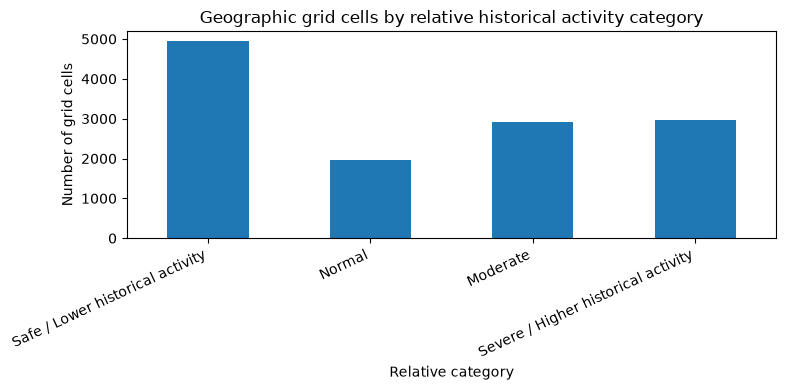

In [24]:
# Country-wise summary from the original dataset, if a country column was found in EDA.
# Otherwise, clearly report that country names need geographic enrichment.
if COUNTRY_SOURCE_COL:
    country_final = (
        raw[COUNTRY_SOURCE_COL].fillna("Unknown").astype(str)
        .value_counts().rename_axis("Country").reset_index(name="Earthquake records")
    )
    print("COUNTRY-WISE EARTHQUAKE RECORDS (from the supplied CSV)")
    display(country_final)
else:
    print("Country-wise final ranking unavailable: no country column exists in the supplied CSV.")
    print("Add a trusted country field / geographic boundary lookup before presenting country names.")

# Final geographic rankings based on grid aggregates
show_cols = ["lat_cell", "lon_cell", "event_count", "mean_magnitude", "max_magnitude", "risk_category"]
show_cols = [c for c in show_cols if c in grid.columns]

print("LOWER HISTORICAL ACTIVITY GRID CELLS (lowest recorded event counts)")
display(grid.sort_values(["event_count", "max_magnitude"], ascending=[True, True])[show_cols].head(15))

print("HIGHER HISTORICAL ACTIVITY GRID CELLS (highest recorded event counts / relative category)")
display(grid.sort_values(["event_count", "max_magnitude"], ascending=[False, False])[show_cols].head(15))

print("ALL GRID CELLS SORTED FROM LOWER TO HIGHER HISTORICAL ACTIVITY")
display(grid.sort_values(["event_count", "max_magnitude"], ascending=[True, True])[show_cols])

# Visual summary of categories
category_order = ["Safe / Lower historical activity", "Normal", "Moderate", "Severe / Higher historical activity"]
category_counts = grid["risk_category"].value_counts().reindex(category_order, fill_value=0)
display(category_counts.rename_axis("Relative historical activity category").to_frame("Number of grid cells"))

plt.figure(figsize=(8, 4))
category_counts.plot(kind="bar")
plt.title("Geographic grid cells by relative historical activity category")
plt.xlabel("Relative category")
plt.ylabel("Number of grid cells")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [25]:
print(df[["latitude", "longitude"]].describe())

print("Invalid latitude:",
      (~df["latitude"].between(-90, 90)).sum())

print("Invalid longitude:",
      (~df["longitude"].between(-180, 180)).sum())

print(df[["latitude", "longitude", "place"]].sample(10))

           latitude     longitude
count  93931.000000  93931.000000
mean       4.389006     39.626308
std       30.671444    121.270617
min      -84.493200   -179.999700
25%      -19.037450    -69.726150
50%        1.793400     98.467400
75%       30.323100    141.931700
max       87.375200    179.999400
Invalid latitude: 0
Invalid longitude: 0
       latitude  longitude                                      place
60778  -10.1334   160.9825    108 km WNW of Kirakira, Solomon Islands
61784    3.9157   -85.9837           off the coast of Central America
24924  -58.7905   -25.2951              South Sandwich Islands region
72484  -20.7057   -68.7581                 77 km NW of Ollagüe, Chile
91329  -14.8022  -175.6129  178 km SSE of Mata-Utu, Wallis and Futuna
73234   51.1490   158.5587          148 km ESE of Ozernovskiy, Russia
62599   -8.0013   117.8225            59 km NE of Pototano, Indonesia
66225   -4.8520   153.0960     107 km ESE of Kokopo, Papua New Guinea
69463   -5.3606   152.0

In [26]:
# Check whether latitude and longitude may have been swapped
swapped_candidates = df[
    df["latitude"].abs() > 90
]

# Check suspicious coordinates near the poles
print("Near poles:", (df["latitude"].abs() > 80).sum())

# Check missing coordinates
print(df[["latitude", "longitude"]].isna().sum())

# Inspect random records alongside their place descriptions
print(
    df[["latitude", "longitude", "place"]]
    .sample(20, random_state=42)
    .to_string(index=False)
)

Near poles: 168
latitude     0
longitude    0
dtype: int64
 latitude  longitude                                       place
  16.9677   -85.3777        76 km NE of Savannah Bight, Honduras
  37.4051    20.3878                52 km SW of Lithakiá, Greece
  37.0561   141.2274                     30 km E of Iwaki, Japan
 -32.3699   179.3824               south of the Kermadec Islands
  29.6946   142.2399                   Izu Islands, Japan region
 -57.7429   -25.7569               South Sandwich Islands region
  42.9276   144.0449                 5 km SW of Shiranuka, Japan
  36.5466    23.0342                   15 km S of Géfyra, Greece
 -43.5412    39.1615                Prince Edward Islands region
  52.9277   160.0982 99 km E of Petropavlovsk-Kamchatsky, Russia
  44.2409   148.5100              120 km SSE of Kuril’sk, Russia
 -22.9137  -175.1313                  175 km S of ‘Ohonua, Tonga
 -19.3969   -69.2977                   16 km SE of Camiña, Chile
  14.1529   -92.9659           